In [1]:
REPO = "/kaggle/working/ComputerVisionAndImageProcessing"
!git clone -q https://github.com/nataliachoszczyk/ComputerVisionAndImageProcessing.git {REPO} 2>/dev/null || git -C {REPO} pull
%cd {REPO}/01-image-modification

/kaggle/working/ComputerVisionAndImageProcessing/01-image-modification


In [2]:
from pathlib import Path

if not Path("/tmp/div2k").exists():
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
    !unzip -q /tmp/DIV2K_train_HR.zip -d /tmp/div2k
    !unzip -q /tmp/DIV2K_valid_HR.zip -d /tmp/div2k
    !rm /tmp/DIV2K_*.zip

print(len(list(Path("/tmp/div2k").rglob("*.png"))))

DIV2K_train_HR.zip  100%[===================>]   3.29G  19.0MB/s    in 3m 5s   
DIV2K_valid_HR.zip  100%[===================>] 428.19M  24.3MB/s    in 37s     
900


In [3]:
from data import cut_patches
from sr_data_preparation import make_lr_patches

PATCHES = "/tmp/patches"

if not Path(PATCHES).exists():
    cut_patches("/tmp/div2k", PATCHES)
    make_lr_patches(PATCHES)

train:   0%|          | 0/750 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

test:   0%|          | 0/100 [00:00<?, ?it/s]

train/lr_x4:   0%|          | 0/30000 [00:00<?, ?it/s]

val/lr_x4:   0%|          | 0/1757 [00:00<?, ?it/s]

test/lr_x4:   0%|          | 0/3598 [00:00<?, ?it/s]

train/lr_x8:   0%|          | 0/30000 [00:00<?, ?it/s]

val/lr_x8:   0%|          | 0/1757 [00:00<?, ?it/s]

test/lr_x8:   0%|          | 0/3598 [00:00<?, ?it/s]

In [4]:
for split in ["train", "val", "test"]:
    print(split, {d.name: len(list(d.glob("*.png"))) for d in sorted(Path(PATCHES, split).iterdir())})

train {'lr_x4': 30000, 'lr_x8': 30000, 'original': 30000}
val {'lr_x4': 1757, 'lr_x8': 1757, 'original': 1757}
test {'lr_x4': 3598, 'lr_x8': 3598, 'original': 3598}


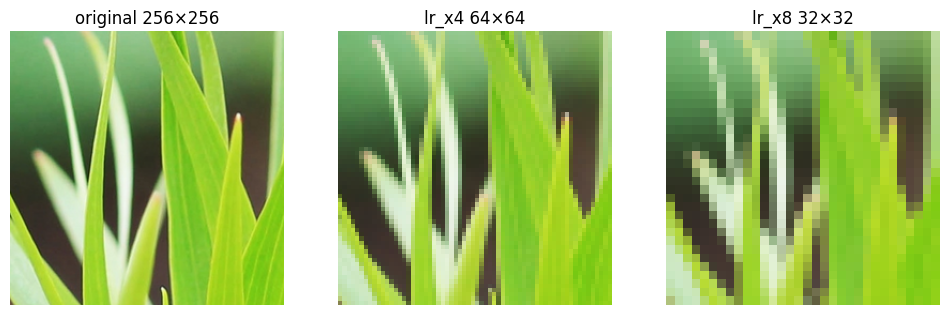

In [5]:
import cv2
import matplotlib.pyplot as plt

name = sorted(Path(PATCHES, "test/original").glob("*.png"))[80].name
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, folder in zip(axes, ["original", "lr_x4", "lr_x8"]):
    img = cv2.cvtColor(cv2.imread(f"{PATCHES}/test/{folder}/{name}"), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{folder} {img.shape[1]}×{img.shape[0]}")
    ax.axis("off")

In [6]:
!pip install -q lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.9 MB/s eta 0:00:00


In [7]:
import shutil
import numpy as np
import pandas as pd
import torch

from data import PatchDataset, PATCH_SIZE
from metrics import evaluate

WORK = Path("/kaggle/working")
device = "cuda" if torch.cuda.is_available() else "cpu"

for f in Path("/kaggle/input").rglob("*"):
    if f.name.startswith(("unet_x", "history_x", "bicubic_x")):
        shutil.copy(f, WORK)


def bicubic(lr):
    imgs = lr.cpu().permute(0, 2, 3, 1).numpy()
    up = [cv2.resize(img, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_CUBIC) for img in imgs]
    return torch.from_numpy(np.stack(up)).permute(0, 3, 1, 2).clamp(0, 1)


results = {}
for scale in [4, 8]:
    csv = WORK / f"bicubic_x{scale}.csv"
    if not csv.exists():
        test = PatchDataset(f"{PATCHES}/test/lr_x{scale}", f"{PATCHES}/test/original")
        evaluate(bicubic, test, device).to_csv(csv)
    results[f"bicubic_x{scale}"] = pd.read_csv(csv, index_col=0)

pd.DataFrame({name: df.mean() for name, df in results.items()}).T

  0%|          | 0/225 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  6%|▌         | 13.6M/233M [00:00<00:01, 142MB/s]
 15%|█▍        | 34.9M/233M [00:00<00:01, 189MB/s]
 23%|██▎       | 53.0M/233M [00:00<00:00, 189MB/s]
 31%|███       | 71.1M/233M [00:00<00:00, 189MB/s]
 38%|███▊      | 89.1M/233M [00:00<00:00, 188MB/s]
 47%|████▋     | 110M/233M [00:00<00:00, 198MB/s] 
 55%|█████▌    | 129M/233M [00:00<00:00, 195MB/s]
 63%|██████▎   | 148M/233M [00:00<00:00, 192MB/s]
 71%|███████   | 166M/233M [00:00<00:00, 190MB/s]
 79%|███████▉  | 184M/233M [00:01<00:00, 185MB/s]
 87%|████████▋ | 202M/233M [00:01<00:00, 182MB/s]
100%|██████████| 233M/233M [00:01<00:00, 193MB/s]


  0%|          | 0/225 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS,SNE
bicubic_x4,29.577713,0.770909,0.382905,642.477559
bicubic_x8,26.619552,0.627290,0.557436,1158.917273


In [8]:
from model import UNet

model = UNet(scale=4)
x = torch.rand(2, 3, 64, 64)
print(model(x).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([2, 3, 256, 256])
1925667


In [9]:
from model import UNet
from training import train

for scale in [4, 8]:
    if (WORK / f"unet_x{scale}.pt").exists():
        continue
    train_set = PatchDataset(f"{PATCHES}/train/lr_x{scale}", f"{PATCHES}/train/original")
    val_set = PatchDataset(f"{PATCHES}/val/lr_x{scale}", f"{PATCHES}/val/original")
    history = train(UNet(scale=scale), train_set, val_set, WORK / f"unet_x{scale}.pt", epochs=25)
    history.to_csv(WORK / f"history_x{scale}.csv", index=False)

In [10]:
device = "cuda" if torch.cuda.is_available() else "cpu"

for scale in [4, 8]:
    model = UNet(scale=scale)
    model.load_state_dict(torch.load(WORK / f"unet_x{scale}.pt", map_location=device))
    model.to(device).eval()
    test = PatchDataset(f"{PATCHES}/test/lr_x{scale}", f"{PATCHES}/test/original")
    results[f"unet_x{scale}"] = evaluate(model, test, device)

table = pd.DataFrame({name: df.mean() for name, df in results.items()}).T
table = table.loc[["bicubic_x4", "unet_x4", "bicubic_x8", "unet_x8"]]
table.to_csv(WORK / "results.csv")
table.round(4)

  0%|          | 0/225 [00:00<?, ?it/s]

  0%|          | 0/225 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS,SNE
bicubic_x4,29.5777,0.7709,0.3829,642.4776
unet_x4,30.9966,0.8168,0.2633,480.4622
bicubic_x8,26.6196,0.6273,0.5574,1158.9173
unet_x8,27.6109,0.6746,0.4248,965.9471


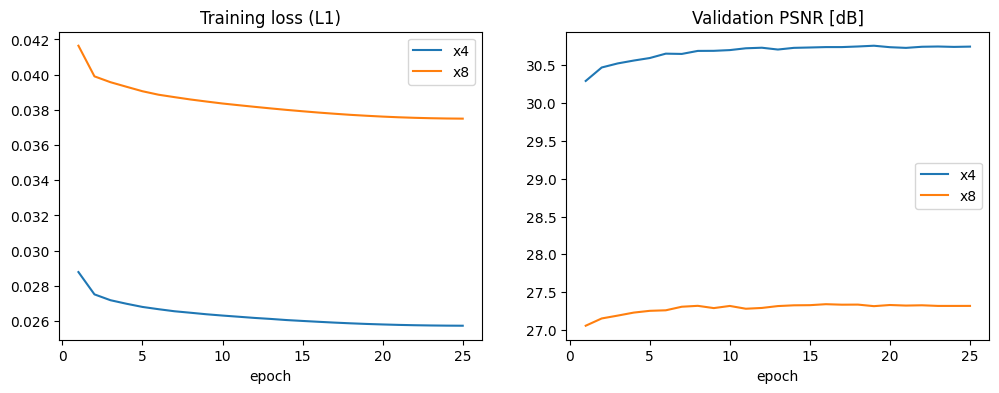

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for scale in [4, 8]:
    h = pd.read_csv(WORK / f"history_x{scale}.csv")
    axes[0].plot(h.epoch, h.train_loss, label=f"x{scale}")
    axes[1].plot(h.epoch, h.val_psnr, label=f"x{scale}")
axes[0].set(title="Training loss (L1)", xlabel="epoch")
axes[1].set(title="Validation PSNR [dB]", xlabel="epoch")
for ax in axes:
    ax.legend()
fig.savefig(WORK / "learning_curves.png", dpi=150, bbox_inches="tight")

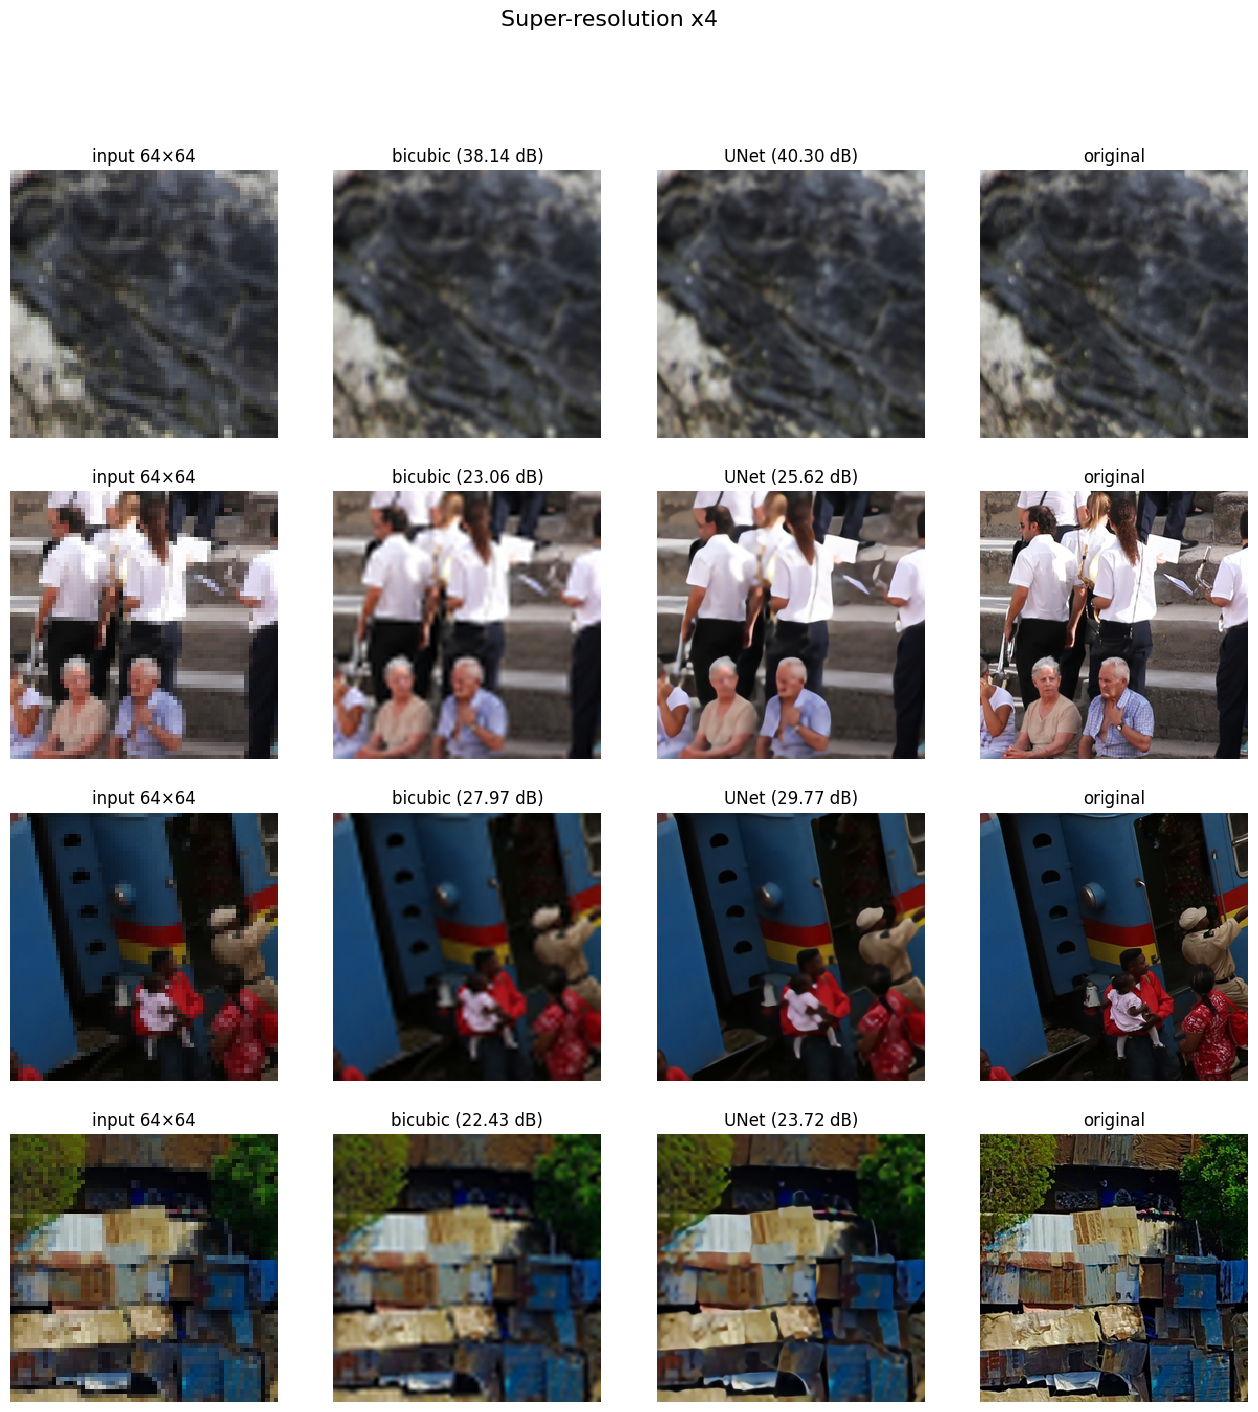

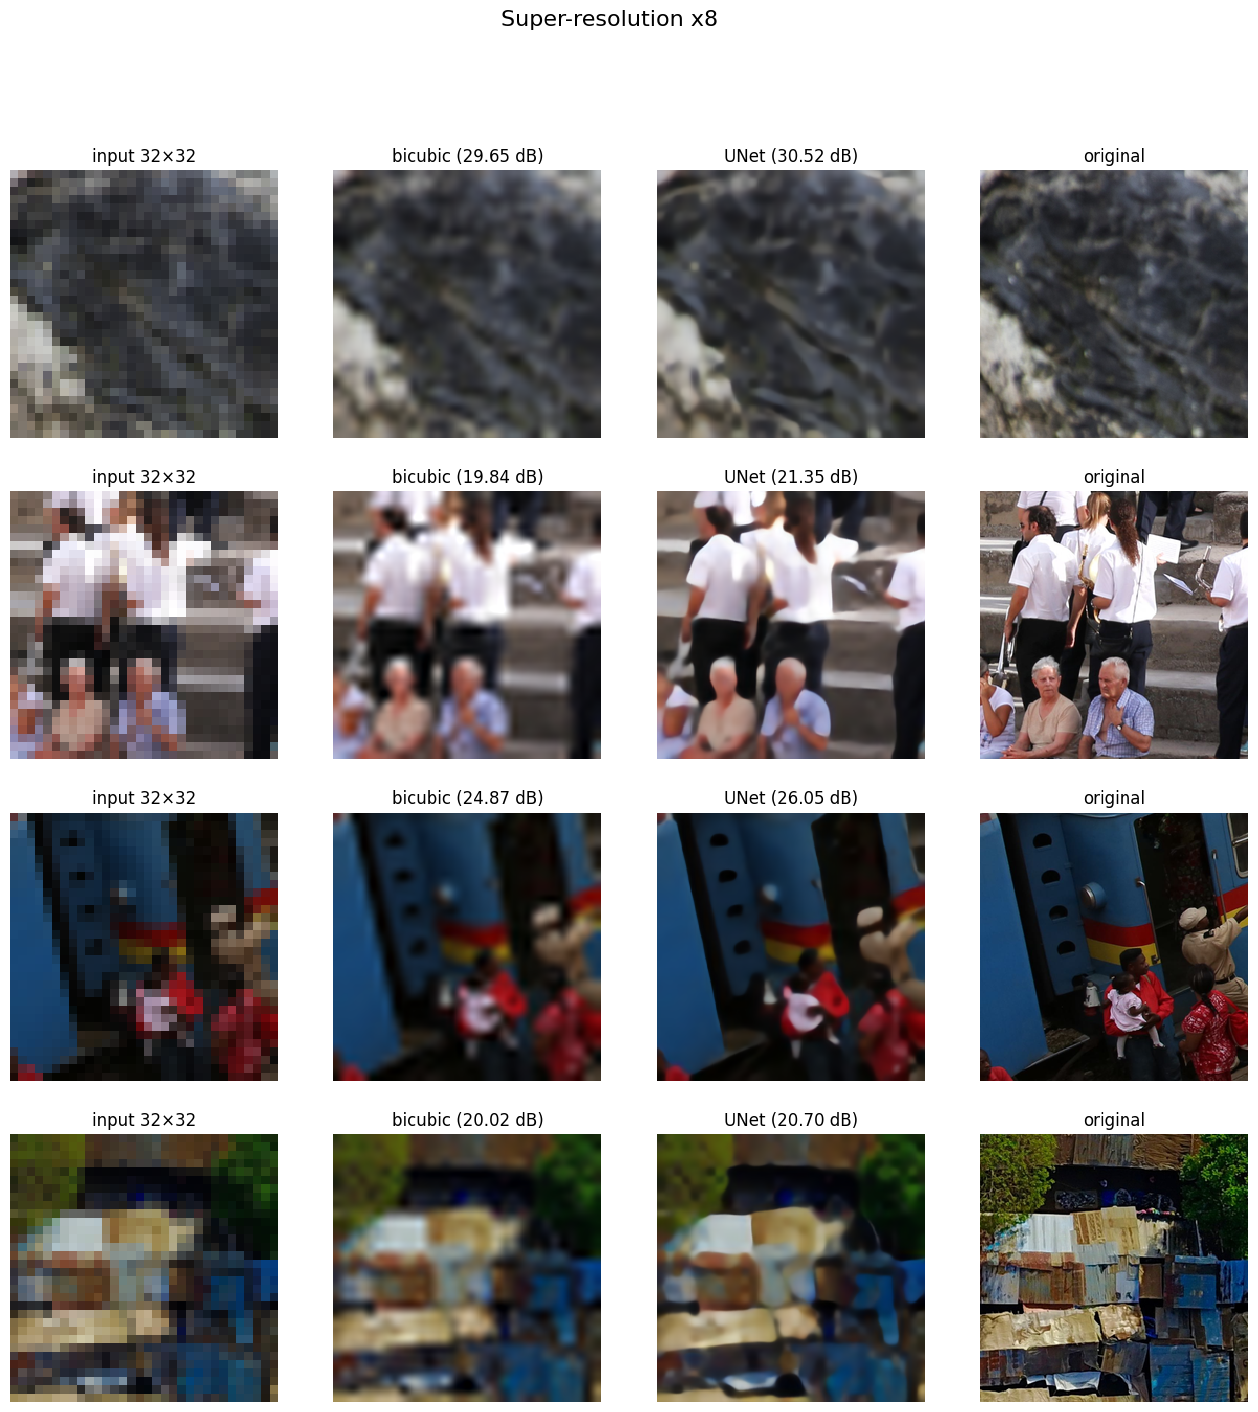

In [12]:
from data import load_image
from metrics import psnr

names = sorted(p.name for p in Path(PATCHES, "test/original").glob("*.png"))[::900]

for scale in [4, 8]:
    model = UNet(scale=scale)
    model.load_state_dict(torch.load(WORK / f"unet_x{scale}.pt", map_location="cpu"))
    model.eval()

    fig, axes = plt.subplots(len(names), 4, figsize=(16, 4 * len(names)))
    for row, name in zip(axes, names):
        lr = load_image(f"{PATCHES}/test/lr_x{scale}/{name}")[None]
        hr = load_image(f"{PATCHES}/test/original/{name}")[None]
        with torch.no_grad():
            images = {
                f"input {256 // scale}×{256 // scale}": lr,
                "bicubic": bicubic(lr),
                "UNet": model(lr).clamp(0, 1),
                "original": hr,
            }
        for ax, (title, img) in zip(row, images.items()):
            if title in ("bicubic", "UNet"):
                title += f" ({psnr(img, hr).item():.2f} dB)"
            ax.imshow(img[0].permute(1, 2, 0).numpy(), interpolation="nearest")
            ax.set_title(title)
            ax.axis("off")
    fig.suptitle(f"Super-resolution x{scale}", fontsize=16)
    fig.savefig(WORK / f"comparison_x{scale}.png", dpi=100, bbox_inches="tight")